In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, random_split
import numpy as np
import os
import matplotlib.pyplot as plt
from tqdm import tqdm

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [3]:
transform_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.491, 0.482, 0.447),
                         (0.202, 0.199, 0.201)),
])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.491, 0.482, 0.447),
                         (0.202, 0.199, 0.201)),
])

dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform_train
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform_test
)

# 90/10 split (as paper)
train_size = int(0.9 * len(dataset))
val_size = len(dataset) - train_size

train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

batch_size = 256  # paper setting

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=4)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=4)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=4)

100%|██████████| 170M/170M [00:02<00:00, 81.2MB/s] 


In [4]:
from torchvision.models import resnet34
import torch.nn as nn

teacher = resnet34(pretrained=False)

teacher.conv1 = nn.Conv2d(
    3, 64, kernel_size=3, stride=1, padding=1, bias=False
)

teacher.maxpool = nn.Identity()

teacher.fc = nn.Linear(teacher.fc.in_features, 10)

teacher = teacher.to(device)

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


In [5]:
teacher

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): Identity()
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), p

In [6]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.SGD(
    teacher.parameters(),
    lr=0.1,
    momentum=0.9,
    weight_decay=5e-4
)

scheduler = optim.lr_scheduler.MultiStepLR(
    optimizer,
    milestones=[100, 150],
    gamma=0.1
)

In [7]:
num_epochs = 200

best_val_acc = 0.0
train_losses = []
val_accuracies = []

for epoch in range(num_epochs):
    teacher.train()
    running_loss = 0.0
    correct = 0
    total = 0

    loop = tqdm(train_loader)
    for images, labels in loop:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = teacher(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

        loop.set_description(f"Epoch [{epoch+1}/{num_epochs}]")
        loop.set_postfix(loss=loss.item())

    scheduler.step()

    train_acc = 100 * correct / total
    train_loss = running_loss / len(train_loader)

    # Validation
    teacher.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = teacher(images)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

    val_acc = 100 * correct / total

    train_losses.append(train_loss)
    val_accuracies.append(val_acc)

    print(f"Epoch {epoch+1}: "
          f"Train Loss={train_loss:.4f}, "
          f"Train Acc={train_acc:.2f}%, "
          f"Val Acc={val_acc:.2f}%")

    # Save best model
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(teacher.state_dict(), "teacher_resnet34_best.pth")

print("Training Complete")

Epoch [1/50]: 100%|██████████| 176/176 [00:56<00:00,  3.10it/s, loss=1.99]


Epoch 1: Train Loss=2.4315, Train Acc=18.18%, Val Acc=25.32%


Epoch [2/50]: 100%|██████████| 176/176 [00:56<00:00,  3.10it/s, loss=1.67]


Epoch 2: Train Loss=1.7717, Train Acc=33.68%, Val Acc=35.54%


Epoch [3/50]: 100%|██████████| 176/176 [00:57<00:00,  3.05it/s, loss=1.55]


...

Epoch 48: Train Loss=0.2211, Train Acc=92.45%, Val Acc=84.34%


Epoch [49/50]: 100%|██████████| 176/176 [00:59<00:00,  2.97it/s, loss=0.251]


Epoch 49: Train Loss=0.2136, Train Acc=92.72%, Val Acc=82.46%


Epoch [50/50]: 100%|██████████| 176/176 [00:59<00:00,  2.97it/s, loss=0.246]


Epoch 50: Train Loss=0.2155, Train Acc=92.65%, Val Acc=82.44%
Training Complete


In [7]:
teacher.load_state_dict(torch.load("teacher_resnet34_best.pth"))
teacher.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = teacher(images)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

test_acc = 100 * correct / total
print(f"Final Test Accuracy: {test_acc:.2f}%")

Final Test Accuracy: 95.01%


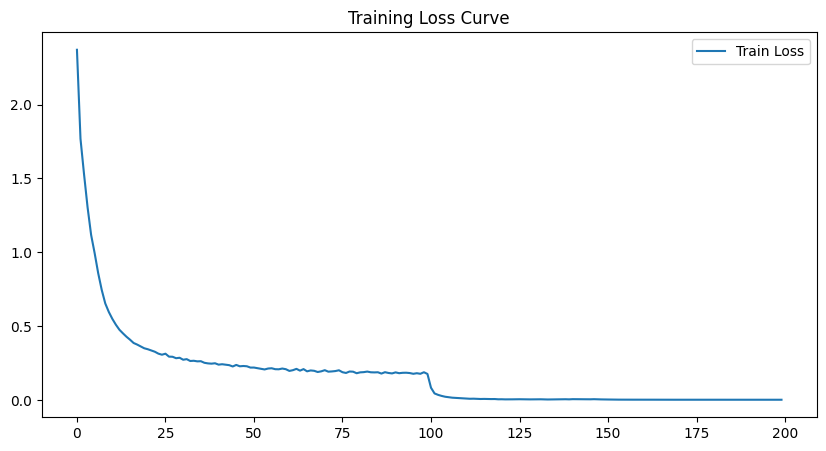

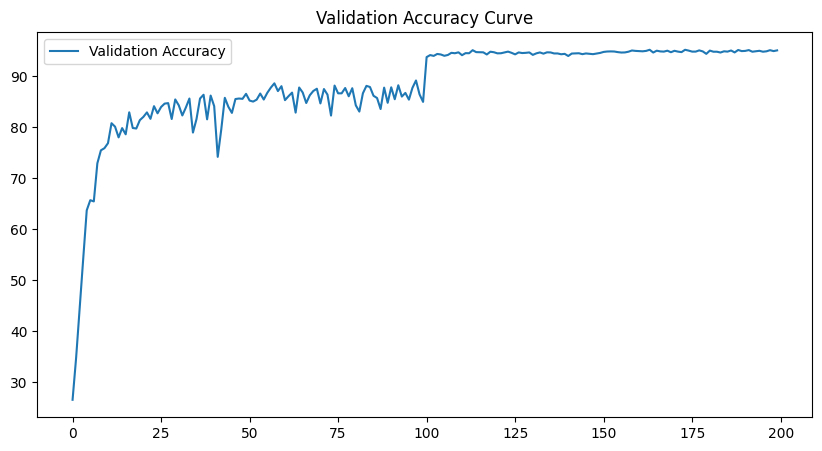

In [8]:
plt.figure(figsize=(10,5))
plt.plot(train_losses, label="Train Loss")
plt.legend()
plt.title("Training Loss Curve")
plt.show()

plt.figure(figsize=(10,5))
plt.plot(val_accuracies, label="Validation Accuracy")
plt.legend()
plt.title("Validation Accuracy Curve")
plt.show()

In [9]:
teacher = resnet34(pretrained=False)
teacher.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
teacher.maxpool = nn.Identity()
teacher.fc = nn.Linear(teacher.fc.in_features, 10)

teacher.load_state_dict(torch.load("teacher_resnet34_best.pth"))
teacher = teacher.to(device)
teacher.eval()

for param in teacher.parameters():
    param.requires_grad = False

In [10]:
student = resnet34(pretrained=False)
student.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
student.maxpool = nn.Identity()

# Remove classifier
student.fc = nn.Identity()

student = student.to(device)

In [11]:
def get_features(model, x):
    features = []

    x = model.conv1(x)
    x = model.bn1(x)
    x = model.relu(x)

    x = model.layer1(x)
    features.append(x)

    x = model.layer2(x)
    features.append(x)

    x = model.layer3(x)
    features.append(x)

    x = model.layer4(x)
    features.append(x)

    return features

In [12]:
def fgsm_attack(model, images, labels, epsilon):
    images = images.clone().detach().requires_grad_(True)
    
    outputs = model(images)
    loss = nn.CrossEntropyLoss()(outputs, labels)
    
    model.zero_grad()
    loss.backward()
    
    adv_images = images + epsilon * images.grad.sign()
    adv_images = torch.clamp(adv_images, -3, 3)
    
    return adv_images.detach()

In [13]:
def student_loss(student_feats_clean, student_feats_adv, teacher_feats_clean):
    total_loss = 0

    for s_clean, s_adv, t_clean in zip(student_feats_clean, student_feats_adv, teacher_feats_clean):
        R = torch.numel(t_clean[0])
        
        loss_clean = ((s_clean - t_clean) ** 2).mean()
        loss_adv = ((s_adv - t_clean) ** 2).mean()
        
        total_loss += (loss_clean + loss_adv)

    return total_loss

In [14]:
optimizer_student = optim.SGD(
    student.parameters(),
    lr=0.1,
    momentum=0.9,
    weight_decay=5e-4
)

scheduler_student = optim.lr_scheduler.MultiStepLR(
    optimizer_student,
    milestones=[100,150],
    gamma=0.1
)

In [15]:
num_epochs = 200
best_loss = float('inf')

for epoch in range(num_epochs):
    student.train()
    running_loss = 0

    loop = tqdm(train_loader)

    for images, labels in loop:
        images, labels = images.to(device), labels.to(device)

        epsilon = np.random.uniform(2/255, 10/255)

        # Generate adversarial batch using teacher
        adv_images = fgsm_attack(teacher, images, labels, epsilon)

        # Extract features
        teacher_feats = get_features(teacher, images)
        student_feats_clean = get_features(student, images)
        student_feats_adv = get_features(student, adv_images)

        loss = student_loss(student_feats_clean, student_feats_adv, teacher_feats)

        optimizer_student.zero_grad()
        loss.backward()
        optimizer_student.step()

        running_loss += loss.item()

        loop.set_description(f"Epoch [{epoch+1}/{num_epochs}]")
        loop.set_postfix(loss=loss.item())

    scheduler_student.step()

    epoch_loss = running_loss / len(train_loader)
    print(f"Epoch {epoch+1}: Student Loss = {epoch_loss:.6f}")

    if epoch_loss < best_loss:
        best_loss = epoch_loss
        torch.save(student.state_dict(), "student_resnet34_best.pth")

print("Student Training Complete")

Epoch [1/25]: 100%|██████████| 176/176 [02:53<00:00,  1.02it/s, loss=0.581]


Epoch 1: Student Loss = 1.319977


Epoch [2/25]: 100%|██████████| 176/176 [02:53<00:00,  1.02it/s, loss=0.518]


Epoch 2: Student Loss = 0.551322


Epoch [3/25]: 100%|██████████| 176/176 [02:53<00:00,  1.01it/s, loss=0.478]


...

Epoch 23: Student Loss = 0.052739


Epoch [24/25]: 100%|██████████| 176/176 [02:54<00:00,  1.01it/s, loss=0.0456]


Epoch 24: Student Loss = 0.050021


Epoch [25/25]: 100%|██████████| 176/176 [02:54<00:00,  1.01it/s, loss=0.0411]


Epoch 25: Student Loss = 0.048817
Student Training Complete


In [16]:
def generate_fgsm_dataset(model, loader, epsilon=8/255):
    model.eval()
    adv_images_list = []
    clean_images_list = []
    labels_list = []

    for images, labels in tqdm(loader):
        images, labels = images.to(device), labels.to(device)

        images.requires_grad = True
        outputs = model(images)
        loss = nn.CrossEntropyLoss()(outputs, labels)

        model.zero_grad()
        loss.backward()

        adv_images = images + epsilon * images.grad.sign()
        adv_images = torch.clamp(adv_images, -3, 3)

        adv_images_list.append(adv_images.detach())
        clean_images_list.append(images.detach())
        labels_list.append(labels.detach())

    return (
        torch.cat(clean_images_list),
        torch.cat(adv_images_list),
        torch.cat(labels_list)
    )

In [17]:
clean_imgs, adv_imgs, labels = generate_fgsm_dataset(teacher, test_loader)

100%|██████████| 40/40 [00:08<00:00,  4.55it/s]


In [18]:
from sklearn.metrics import roc_auc_score

def compute_detection_scores(clean_imgs, adv_imgs):
    teacher.eval()
    student.eval()

    clean_scores = []
    adv_scores = []

    with torch.no_grad():
        for i in range(0, len(clean_imgs), 256):
            clean_batch = clean_imgs[i:i+256].to(device)
            adv_batch = adv_imgs[i:i+256].to(device)

            # Clean
            t_clean = get_features(teacher, clean_batch)
            s_clean = get_features(student, clean_batch)
            outputs_clean = teacher(clean_batch)
            msp_clean = torch.max(torch.softmax(outputs_clean, dim=1), dim=1)[0]

            # Adversarial
            t_adv = get_features(teacher, adv_batch)
            s_adv = get_features(student, adv_batch)
            outputs_adv = teacher(adv_batch)
            msp_adv = torch.max(torch.softmax(outputs_adv, dim=1), dim=1)[0]

            # Feature MAE
            def layer_mae(t_feats, s_feats):
                layer_scores = []
                for t, s in zip(t_feats, s_feats):
                    R = torch.numel(t[0])
                    diff = torch.abs(t - s).view(t.size(0), -1).mean(dim=1)
                    layer_scores.append(diff)
                return torch.stack(layer_scores, dim=1).max(dim=1)[0]

            clean_feat_score = layer_mae(t_clean, s_clean)
            adv_feat_score = layer_mae(t_adv, s_adv)

            clean_final = torch.max(clean_feat_score, 1 - msp_clean)
            adv_final = torch.max(adv_feat_score, 1 - msp_adv)

            clean_scores.append(clean_final.cpu())
            adv_scores.append(adv_final.cpu())

    clean_scores = torch.cat(clean_scores)
    adv_scores = torch.cat(adv_scores)

    labels_clean = torch.zeros(len(clean_scores))
    labels_adv = torch.ones(len(adv_scores))

    all_scores = torch.cat([clean_scores, adv_scores])
    all_labels = torch.cat([labels_clean, labels_adv])

    auroc = roc_auc_score(all_labels.numpy(), all_scores.numpy())

    return auroc

In [19]:
auroc = compute_detection_scores(clean_imgs, adv_imgs)
print("Detection AUROC:", auroc)

Detection AUROC: 0.7754653550000001


In [20]:
import numpy as np

def compute_threshold(clean_imgs, fpr=0.01):
    teacher.eval()
    student.eval()

    scores = []

    with torch.no_grad():
        for i in range(0, len(clean_imgs), 256):
            batch = clean_imgs[i:i+256].to(device)

            t_feats = get_features(teacher, batch)
            s_feats = get_features(student, batch)
            outputs = teacher(batch)
            msp = torch.max(torch.softmax(outputs, dim=1), dim=1)[0]

            layer_scores = []
            for t, s in zip(t_feats, s_feats):
                diff = torch.abs(t - s).view(t.size(0), -1).mean(dim=1)
                layer_scores.append(diff)

            feat_score = torch.stack(layer_scores, dim=1).max(dim=1)[0]
            final_score = torch.max(feat_score, 1 - msp)

            scores.append(final_score.cpu())

    scores = torch.cat(scores).numpy()
    threshold = np.percentile(scores, 100 * (1 - fpr))

    return threshold

In [21]:
threshold = compute_threshold(clean_imgs, fpr=0.01)
print("Detection Threshold:", threshold)

Detection Threshold: 0.6399968


In [27]:
def defense_evaluation(clean_imgs, adv_imgs, labels, threshold):
    teacher.eval()
    student.eval()

    correct_clean = 0
    correct_adv = 0
    total = len(labels)

    with torch.no_grad():
        for i in range(0, total, 256):
            clean_batch = clean_imgs[i:i+256].to(device)
            adv_batch = adv_imgs[i:i+256].to(device)
            label_batch = labels[i:i+256].to(device)

            # ----- CLEAN -----
            t_feats = get_features(teacher, clean_batch)
            s_feats = get_features(student, clean_batch)
            outputs = teacher(clean_batch)
            msp = torch.max(torch.softmax(outputs, dim=1), dim=1)[0]

            layer_scores = []
            for t, s in zip(t_feats, s_feats):
                diff = torch.abs(t - s).view(t.size(0), -1).mean(dim=1)
                layer_scores.append(diff)

            feat_score = torch.stack(layer_scores, dim=1).max(dim=1)[0]
            final_score = torch.max(feat_score, 1 - msp)

            is_adv = final_score >= threshold

            preds_clean = outputs.argmax(dim=1)
            correct_clean += (preds_clean == label_batch).sum().item()

            # ----- ADVERSARIAL -----
            t_feats_adv = get_features(teacher, adv_batch)
            s_feats_adv = get_features(student, adv_batch)
            outputs_adv = teacher(adv_batch)
            msp_adv = torch.max(torch.softmax(outputs_adv, dim=1), dim=1)[0]

            layer_scores_adv = []
            for t, s in zip(t_feats_adv, s_feats_adv):
                diff = torch.abs(t - s).view(t.size(0), -1).mean(dim=1)
                layer_scores_adv.append(diff)

            feat_score_adv = torch.stack(layer_scores_adv, dim=1).max(dim=1)[0]
            final_score_adv = torch.max(feat_score_adv, 1 - msp_adv)

            is_adv_mask = final_score_adv >= threshold

            # Defense switch
            # If detected as adversarial → use student feature into teacher head
            # student_penultimate = s_feats_adv[-1].view(s_feats_adv[-1].size(0), -1)
            student_penultimate = s_feats_adv[-1]
            student_penultimate = nn.functional.adaptive_avg_pool2d(student_penultimate, (1, 1))
            student_penultimate = torch.flatten(student_penultimate, 1)
            
            teacher_fc = teacher.fc

            student_logits = teacher_fc(student_penultimate)
            teacher_preds = outputs_adv.argmax(dim=1)
            student_preds = student_logits.argmax(dim=1)

            final_preds = torch.where(
                is_adv_mask,
                student_preds,
                teacher_preds
            )

            correct_adv += (final_preds == label_batch).sum().item()

    clean_acc = 100 * correct_clean / total
    defense_acc = 100 * correct_adv / total

    return clean_acc, defense_acc

In [28]:
clean_acc, defense_acc = defense_evaluation(clean_imgs, adv_imgs, labels, threshold)

print("Final Clean Accuracy:", clean_acc)
print("Defense Accuracy (FGSM):", defense_acc)

Final Clean Accuracy: 87.32
Defense Accuracy (FGSM): 30.93


In [29]:
def teacher_adv_accuracy(adv_imgs, labels):
    teacher.eval()
    correct = 0
    total = len(labels)

    with torch.no_grad():
        for i in range(0, total, 256):
            batch = adv_imgs[i:i+256].to(device)
            label_batch = labels[i:i+256].to(device)

            outputs = teacher(batch)
            preds = outputs.argmax(dim=1)

            correct += (preds == label_batch).sum().item()

    return 100 * correct / total

In [30]:
teacher_adv_acc = teacher_adv_accuracy(adv_imgs, labels)
print("Teacher Adversarial Accuracy (FGSM):", teacher_adv_acc)

Teacher Adversarial Accuracy (FGSM): 29.61


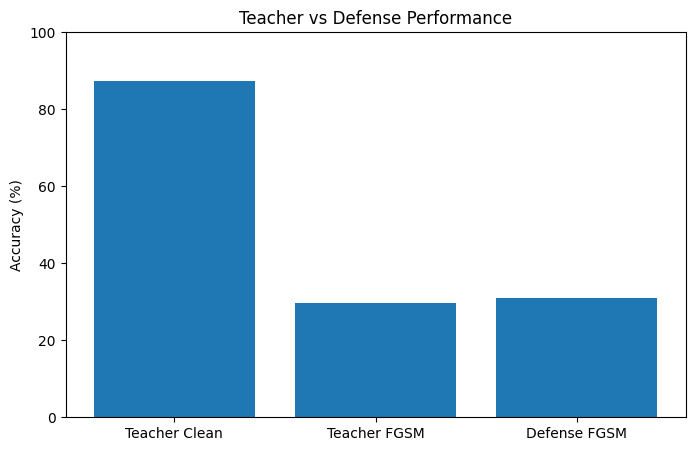

In [31]:
import matplotlib.pyplot as plt

metrics = {
    "Teacher Clean": test_acc,
    "Teacher FGSM": teacher_adv_acc,
    "Defense FGSM": defense_acc
}

plt.figure(figsize=(8,5))
plt.bar(metrics.keys(), metrics.values())
plt.ylabel("Accuracy (%)")
plt.title("Teacher vs Defense Performance")
plt.ylim(0, 100)
plt.show()

In [32]:
print("Detection AUROC:", auroc)

Detection AUROC: 0.7754653550000001


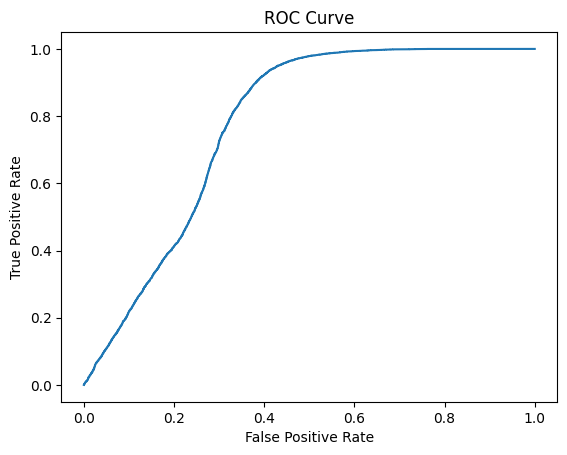

In [33]:
from sklearn.metrics import roc_curve

def plot_roc(clean_imgs, adv_imgs):
    teacher.eval()
    student.eval()

    scores = []
    labels_binary = []

    with torch.no_grad():
        for i in range(0, len(clean_imgs), 256):
            clean_batch = clean_imgs[i:i+256].to(device)
            adv_batch = adv_imgs[i:i+256].to(device)

            t_clean = get_features(teacher, clean_batch)
            s_clean = get_features(student, clean_batch)
            outputs_clean = teacher(clean_batch)
            msp_clean = torch.max(torch.softmax(outputs_clean, dim=1), dim=1)[0]

            t_adv = get_features(teacher, adv_batch)
            s_adv = get_features(student, adv_batch)
            outputs_adv = teacher(adv_batch)
            msp_adv = torch.max(torch.softmax(outputs_adv, dim=1), dim=1)[0]

            def layer_mae(t_feats, s_feats):
                layer_scores = []
                for t, s in zip(t_feats, s_feats):
                    diff = torch.abs(t - s).view(t.size(0), -1).mean(dim=1)
                    layer_scores.append(diff)
                return torch.stack(layer_scores, dim=1).max(dim=1)[0]

            clean_score = torch.max(layer_mae(t_clean, s_clean), 1 - msp_clean)
            adv_score = torch.max(layer_mae(t_adv, s_adv), 1 - msp_adv)

            scores.extend(clean_score.cpu().numpy())
            labels_binary.extend([0]*len(clean_score))

            scores.extend(adv_score.cpu().numpy())
            labels_binary.extend([1]*len(adv_score))

    fpr, tpr, _ = roc_curve(labels_binary, scores)

    plt.figure()
    plt.plot(fpr, tpr)
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve")
    plt.show()
    
plot_roc(clean_imgs, adv_imgs)

In [34]:
!python --version

Python 3.12.12


In [35]:
!pip list

Package                                  Version
---------------------------------------- -------------------
a2a-sdk                                  0.3.23
absl-py                                  1.4.0
accelerate                               1.12.0
access                                   1.1.10.post3
affine                                   2.4.0
aiofiles                                 22.1.0
aiohappyeyeballs                         2.6.1
aiohttp                                  3.13.3
aiosignal                                1.4.0
aiosqlite                                0.22.1
alabaster                                1.0.0
albucore                                 0.0.24
albumentations                           2.0.8
ale-py                                   0.11.2
alembic                                  1.18.1
altair                                   5.5.0
annotated-doc                            0.0.4
annotated-types                          0.7.0
ansicolors                   